In [ ]:
import pandas as pd
df = pd.read_csv('/content/hospital_patient.csv')
print(df.head())



    PatientID    Age      Gender            Department AdmissionDate  \
0    P10001      0.0    Female           Orthopedics      31/02/2024   
1    P10002    150.0    female           Orthopedics      2024-13-40   
2    P10003    999.0         F      general medicine      19-09-2024   
3    P10004     -5.0      Male            Cardiology       17-Apr-25   
4    P10005    200.0      male      GENERAL MEDICINE      13-03-2025   

  DischargeDate                  Diagnosis  TreatmentCost PaymentMode  \
0    31/02/2024    Respiratory Infection         41342.17         UPI   
1    2024-13-40             Hypertension         12447.05         upi   
2    30-09-2024                 Fracture         15433.64        UPI    
3     28-Apr-25            Heart Disease         16290.65         Upi   
4    26-03-2025                 Diabetes          7028.58        CASH   

     PatientStatus  
0    Transferred    
1     Discharged    
2       Admitted    
3     Discharged    
4       Admitted    


In [ ]:
print(df.head())

    PatientID    Age      Gender            Department AdmissionDate  \
0    P10001      0.0    Female           Orthopedics      31/02/2024   
1    P10002    150.0    female           Orthopedics      2024-13-40   
2    P10003    999.0         F      general medicine      19-09-2024   
3    P10004     -5.0      Male            Cardiology       17-Apr-25   
4    P10005    200.0      male      GENERAL MEDICINE      13-03-2025   

  DischargeDate                  Diagnosis  TreatmentCost PaymentMode  \
0    31/02/2024    Respiratory Infection         41342.17         UPI   
1    2024-13-40             Hypertension         12447.05         upi   
2    30-09-2024                 Fracture         15433.64        UPI    
3     28-Apr-25            Heart Disease         16290.65         Upi   
4    26-03-2025                 Diabetes          7028.58        CASH   

     PatientStatus  
0    Transferred    
1     Discharged    
2       Admitted    
3     Discharged    
4       Admitted    


In [ ]:
print(df.shape)

(2025, 10)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   PatientID      2025 non-null   object 
 1   Age            2002 non-null   float64
 2   Gender         2020 non-null   object 
 3   Department     2012 non-null   object 
 4   AdmissionDate  2025 non-null   object 
 5   DischargeDate  2020 non-null   object 
 6   Diagnosis      2015 non-null   object 
 7   TreatmentCost  2010 non-null   float64
 8   PaymentMode    2011 non-null   object 
 9   PatientStatus  2025 non-null   object 
dtypes: float64(2), object(8)
memory usage: 158.3+ KB
None


In [ ]:
print(df.isnull().sum())

PatientID         0
Age              23
Gender            5
Department       13
AdmissionDate     0
DischargeDate     5
Diagnosis        10
TreatmentCost    15
PaymentMode      14
PatientStatus     0
dtype: int64


In [ ]:
print(df.describe())

               Age  TreatmentCost
count  2002.000000    2010.000000
mean     46.962537   18190.995970
std      33.722715    8878.989792
min      -5.000000     857.180000
25%      24.000000   11651.285000
50%      47.000000   16677.660000
75%      68.000000   23169.412500
max     999.000000   69416.170000


# **`DATA PREPROCESSING`**


In [ ]:
df['Gender'] = df['Gender'].astype('string').str.strip().str.title()
df['Gender'] = df['Gender'].replace({
     'M': 'Male',
    'male': 'Male',
    'F': 'Female',
    'female': 'Female',
    '': pd.NA
})

df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])


In [ ]:
df['AdmissionDate'] = pd.to_datetime(
    df['AdmissionDate'].astype('string').str.strip(),
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

df['DischargeDate'] = pd.to_datetime(
    df['DischargeDate'].astype('string').str.strip(),
    format='mixed',
    dayfirst=True,
    errors='coerce'
)


In [ ]:
df['AdmissionDate'] = pd.to_datetime(
    df['AdmissionDate'],
    errors='coerce',
    dayfirst=True
)

In [ ]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df.loc[(df['Age'] < 0) | (df['Age'] > 120), 'Age'] = np.nan
df['Age'] = df['Age'].fillna(df['Age'].median())

In [ ]:
print(df.head(10))

    PatientID   Age  Gender            Department AdmissionDate DischargeDate  \
0    P10001     0.0  Female         Orthopedics             NaT           NaT   
1    P10002    47.0  Female         Orthopedics             NaT           NaT   
2    P10003    47.0  Female    general medicine      2024-09-19    2024-09-30   
3    P10004    47.0    Male          Cardiology      2025-04-17    2025-04-28   
4    P10005    47.0    Male    GENERAL MEDICINE      2025-03-13    2025-03-26   
5    P10006    35.0    Male         Orthopedics      2025-08-07    2025-12-07   
6    P10007    66.0  Female          Cardiology      2025-01-21    2025-01-23   
7    P10008    63.0    Male          Pediatrics      2025-04-13    2025-04-27   
8      P10009  23.0  Female             Neurology    2025-05-02    2025-05-04   
9      P10010   9.0  Female     General medicine     2025-08-03    2025-08-12   

                   Diagnosis  TreatmentCost PaymentMode    PatientStatus  
0    Respiratory Infection       

In [ ]:
df['Department'] = df['Department'].str.strip().str.title()
df['Department'] = df['Department'].fillna('Unknown')
print(df['Department'].isnull().sum())



0


In [ ]:
df['PaymentMode'] = (
    df['PaymentMode']
    .astype('string')
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
    .fillna('UNKNOWN')
)




In [ ]:
df['TreatmentCost'] = pd.to_numeric(
    df['TreatmentCost'], errors='coerce')
median_cost = df['TreatmentCost'].median()
df['TreatmentCost'] = df['TreatmentCost'].fillna(median_cost)

In [ ]:
mode_diagnosis = df['Diagnosis'].mode()[0]
df['Diagnosis'] = df['Diagnosis'].fillna(mode_diagnosis)

In [ ]:
print(df.isnull().sum())

PatientID        0
Age              0
Gender           0
Department       0
AdmissionDate    2
DischargeDate    7
Diagnosis        0
TreatmentCost    0
PaymentMode      0
PatientStatus    0
dtype: int64


In [ ]:
df = df.drop_duplicates()

In [ ]:
print(df.shape)

(2000, 10)


# **EDA**


In [ ]:
categorical_cols = [
    'Gender', 'Department', 'Diagnosis',
    'PaymentMode', 'PatientStatus'
]
for col in categorical_cols:
    print(f"\n{col} Category Counts:")
    print(df[col].value_counts(dropna=False))

    print("Most Common Category:")
    print(df[col].mode().tolist())


Gender Category Counts:
Gender
Female    1009
Male       991
Name: count, dtype: Int64
Most Common Category:
['Female']

Department Category Counts:
Department
General Medicine    633
Emergency           312
Cardiology          308
Orthopedics         293
Pediatrics          257
Neurology           184
Unknown              13
Name: count, dtype: int64
Most Common Category:
['General Medicine']

Diagnosis Category Counts:
Diagnosis
Fever                        340
Heart Disease                297
Migraine                     286
Hypertension                 282
Diabetes                     270
Fracture                     262
Respiratory Infection        255
  Respiratory Infection        2
  Fracture                     2
  Heart Disease                2
  Hypertension                 1
  Diabetes                     1
Name: count, dtype: int64
Most Common Category:
['Fever']

PaymentMode Category Counts:
PaymentMode
INSURANCE    610
UPI          569
CASH         472
CARD         336


In [ ]:
numerical_cols = ['Age', 'TreatmentCost']
for col in numerical_cols:
    print("\nAnalysis of", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Standard Deviation:", df[col].std())


Analysis of Age
Mean: 46.3365
Median: 47.0
Minimum: 0.0
Maximum: 90.0
Standard Deviation: 25.680693463346735

Analysis of TreatmentCost
Mean: 18180.697740000003
Median: 16677.66
Minimum: 857.18
Maximum: 69416.17
Standard Deviation: 8859.521741003413


In [ ]:
categorical_cols = ['Gender','Department','Diagnosis','PaymentMode','PatientStatus']
for col in categorical_cols:
    print("\nColumn:", col)





Column: Gender

Column: Department

Column: Diagnosis

Column: PaymentMode

Column: PatientStatus


In [ ]:
print("\nCategory Counts:")
print(df[col].value_counts(dropna=False))


Category Counts:
PatientStatus
Discharged         1567
Admitted            323
Transferred         102
  Discharged          5
  Admitted            2
  Transferred         1
Name: count, dtype: int64


In [ ]:
print("\nMost Common Category:")
print(df[col].mode().tolist())


Most Common Category:
['Discharged']


DATA VISUALIZATION
**`bold text`**


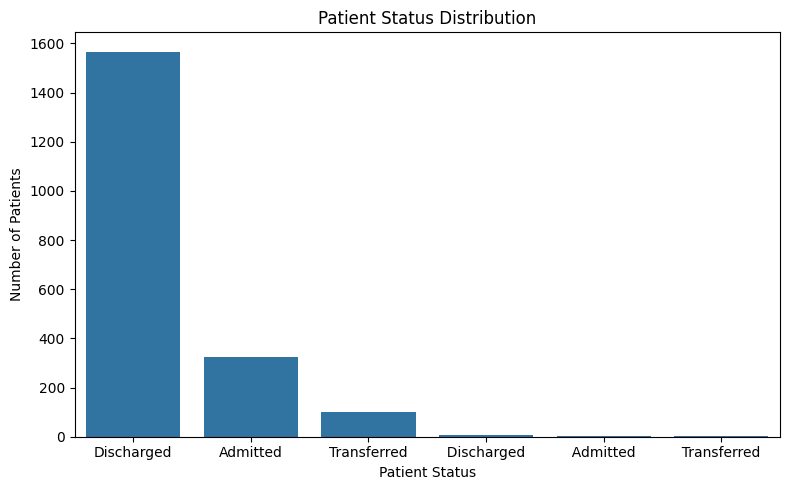

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='PatientStatus',
    order=df['PatientStatus'].value_counts().index
)

plt.title('Patient Status Distribution')
plt.xlabel('Patient Status')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

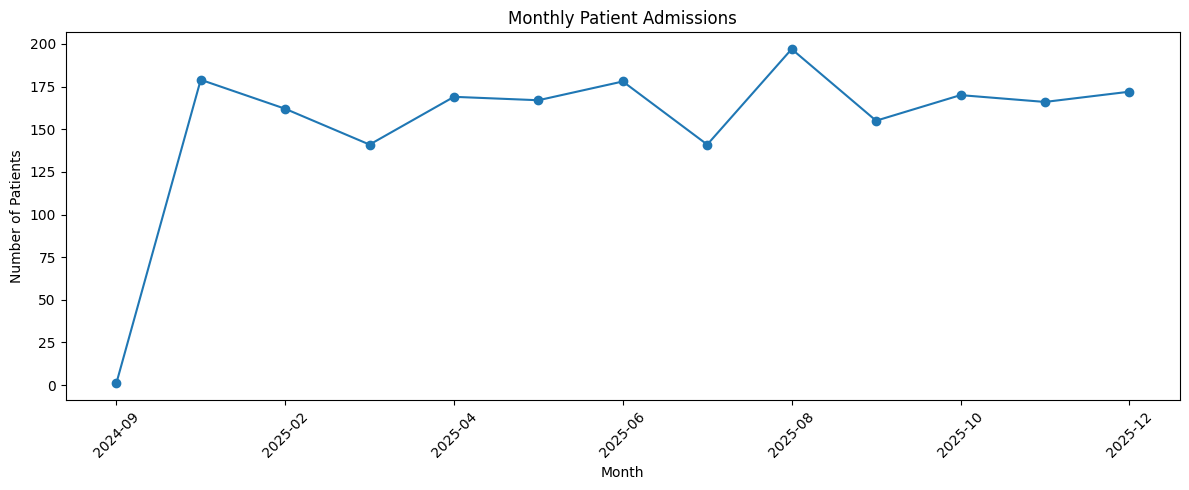

In [ ]:
df['AdmissionDate'] = pd.to_datetime(
    df['AdmissionDate'], errors='coerce'
)

monthly_admissions = (
    df.dropna(subset=['AdmissionDate'])
      .groupby(df['AdmissionDate'].dropna().dt.to_period('M'))
      .size()
      .sort_index()
)

monthly_admissions.index = monthly_admissions.index.astype(str)

plt.figure(figsize=(12, 5))
monthly_admissions.plot(kind='line', marker='o')

plt.title('Monthly Patient Admissions')
plt.xlabel('Month')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

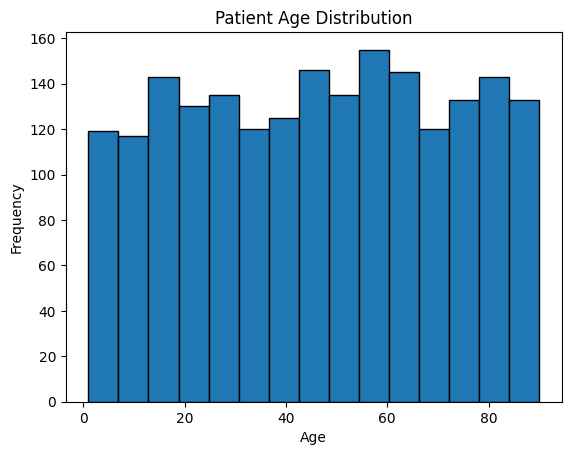

In [ ]:
age = pd.to_numeric(df['Age'], errors='coerce')
age = age[age.between(1, 110)]
age.plot(kind='hist', bins=15, edgecolor='black')
plt.title('Patient Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


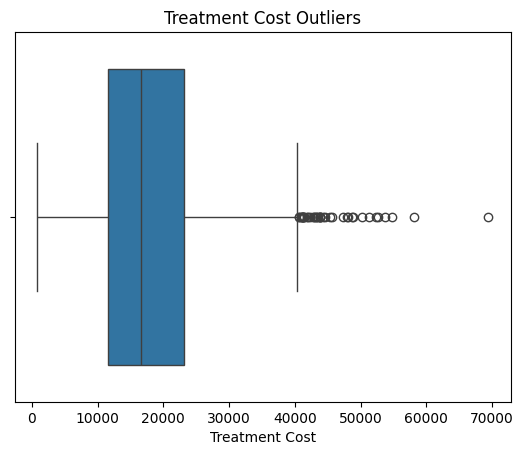

In [ ]:
cost = pd.to_numeric(df['TreatmentCost'], errors='coerce')
sns.boxplot(x=cost.dropna())
plt.title('Treatment Cost Outliers')
plt.xlabel('Treatment Cost')
plt.show()

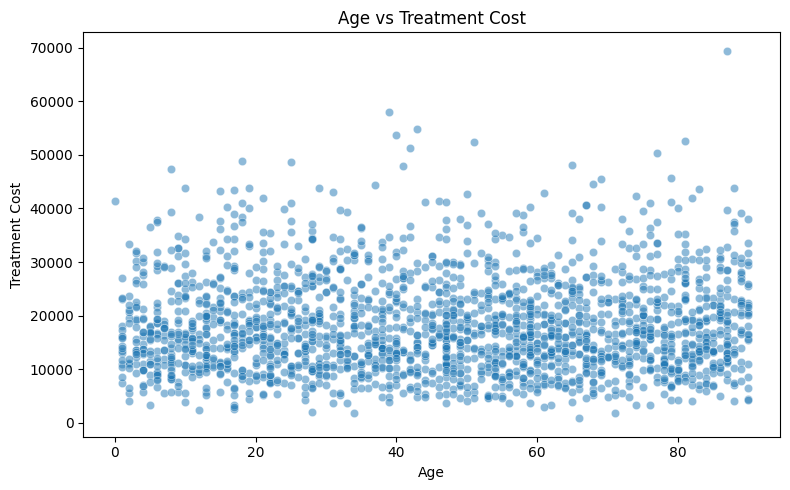

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='TreatmentCost',
    alpha=0.5
)

plt.title('Age vs Treatment Cost')
plt.xlabel('Age')
plt.ylabel('Treatment Cost')
plt.tight_layout()
plt.show()

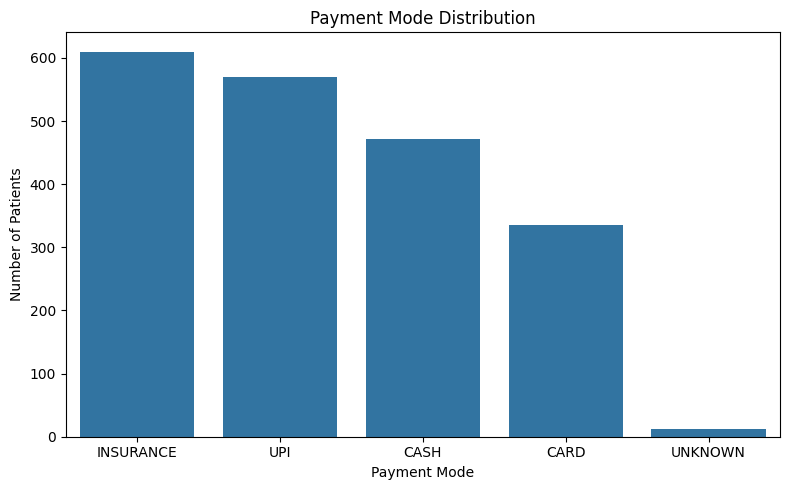

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='PaymentMode',
    order=df['PaymentMode'].value_counts().index
)

plt.title('Payment Mode Distribution')
plt.xlabel('Payment Mode')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

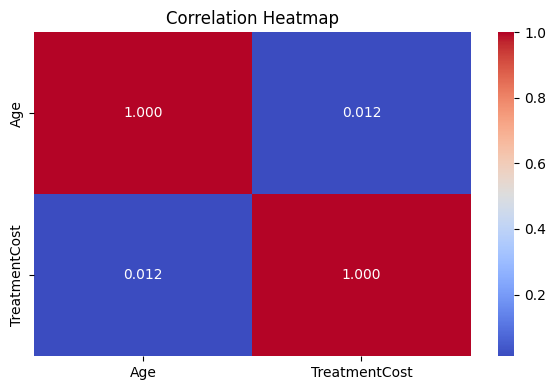

In [ ]:
plt.figure(figsize=(6, 4))

correlation = df[['Age', 'TreatmentCost']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.3f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

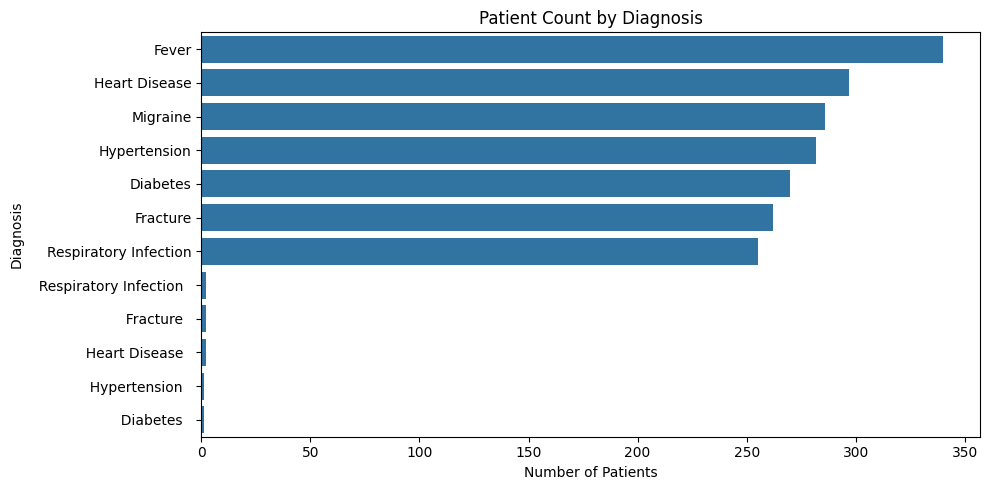

In [ ]:
plt.figure(figsize=(10, 5))

order = df['Diagnosis'].value_counts().index

sns.countplot(
    data=df,
    y='Diagnosis',
    order=order
)

plt.title('Patient Count by Diagnosis')
plt.xlabel('Number of Patients')
plt.ylabel('Diagnosis')
plt.tight_layout()
plt.show()

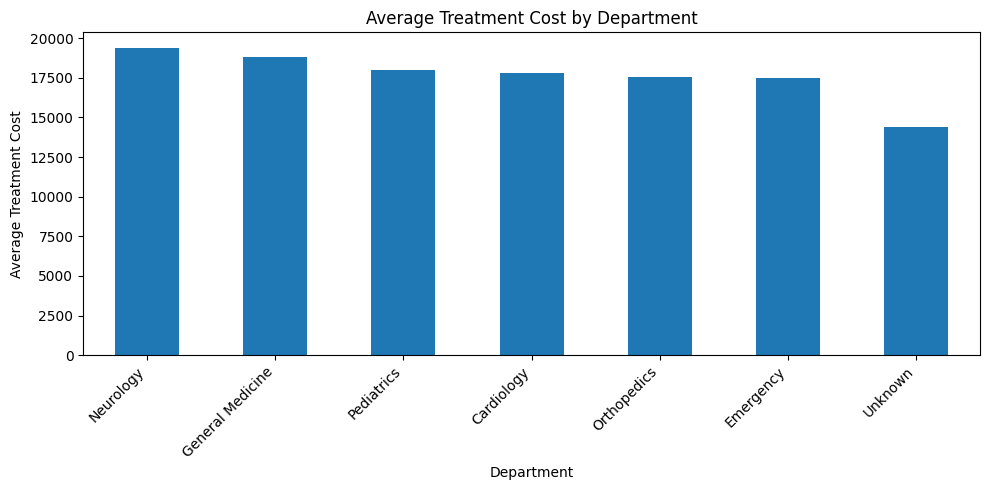

In [ ]:
deptcost = (
    df.groupby('Department')['TreatmentCost']
      .mean()
      .sort_values(ascending=False)
)

deptcost.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Average Treatment Cost by Department')
plt.xlabel('Department')
plt.ylabel('Average Treatment Cost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()